# Linear buckling analysis of a cylinder under torsion

Two torsional buckling problems of circular cylinders of `Quad4` elements:

1. the cylinders Z11 and Z33 of Castro et al. (2014), two unsymmetric
   laminates, with the boundary conditions CC2 of that paper, compared with
   the pure-torsion intercepts of their Fig. 13;
2. an isotropic cylinder with simply supported edges, compared with the
   critical shear stress of Batdorf, Stein and Schildcrout (1947).

The membrane prestress is a uniform shear resultant given to each element
with `update_KG_given_stress`, and the eigenvalue problem is solved with
`pyfe3d.solver.linear_buckling`, see
[Linear buckling and natural frequencies](../eigenvalue_analyses.rst). The
laminate of each element is oriented by a material direction along the axis
of the cylinder, see [Conventions](../conventions.rst); the element is
described in [Quad4: assumed transverse shear strains (MITC4)](../shell_quad4.rst).
The full references are at the end of the notebook.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from numpy import isclose
from scipy.sparse import coo_matrix

from pyfe3d import DOF, DOUBLE, INT, Quad4, Quad4Data, Quad4Probe
from pyfe3d.shellprop_utils import laminated_plate, isotropic_plate
from pyfe3d.solver import linear_buckling

## The model

The axis of the cylinder is the global $z$ axis. The mesh has `ntheta`
nearly square elements around the circumference, an odd number of nodes along
the length, so that a ring of nodes lies at mid-length, and the last column
of nodes is replaced by the first one to close the cylinder. The vector $(0,
0, 1)$ given to `update_rotation_matrix` sets the element $x$ axis, and the
material direction of the laminate, along the axis of the cylinder; the
element normal points outwards. The membrane prestress in the element frame
is then $(N_{xx}, N_{yy}, N_{xy}) = (0, 0, N_{xy})$, the torsion load.

The boundary conditions are constraints on the radial and circumferential
displacements and rotations, whose directions change from node to node. The
matrix $\boldsymbol{T}$ below, $\boldsymbol{u}_{global} = \boldsymbol{T}
\boldsymbol{u}_{cyl}$, rotates the nodal dofs to the cylindrical directions
$(u_r, u_\theta, u_z, r_r, r_\theta, r_z)$, and the matrices become
$\boldsymbol{T}^\top \boldsymbol{K} \boldsymbol{T}$:

In [2]:
def cylindrical_transformation(ncoords):
    theta = np.arctan2(ncoords[:, 1], ncoords[:, 0])
    c = np.cos(theta)
    s = np.sin(theta)
    one = np.ones_like(c)
    zero = np.zeros_like(c)
    # columns: radial, circumferential and axial unit vectors
    Q = np.array([[c, -s, zero],
                  [s, c, zero],
                  [zero, zero, one]])
    rows, cols, vals = [], [], []
    base = DOF*np.arange(len(theta))
    for offset in (0, 3):
        for i in range(3):
            for j in range(3):
                rows.append(base + offset + i)
                cols.append(base + offset + j)
                vals.append(Q[i, j])
    N = DOF*len(theta)
    return coo_matrix((np.concatenate(vals), (np.concatenate(rows),
                       np.concatenate(cols))), shape=(N, N)).tocsc()

The function below builds the cylinder of radius `R` and length `L`,
assembles $\boldsymbol{K}_{C0}$ and $\boldsymbol{K}_G$ for the shear
resultant `Nxy`, applies the boundary conditions `bc` in cylindrical
coordinates and solves $(\boldsymbol{K}_{C0} + \lambda \boldsymbol{K}_G)
\boldsymbol{u} = \boldsymbol{0}$. One node at mid-length is held axially to
remove the rigid axial translation. `linear_buckling` equilibrates the
diagonal, estimates the shift of the Cayley transformation and verifies that
no lower load multiplier was missed:

In [3]:
def cylinder_torsion(prop, R, L, ntheta, Nxy, bc, num_eigvalues=6):
    data = Quad4Data()
    probe = Quad4Probe()
    nlength = int(ntheta*L/(2*np.pi*R))
    nlength += 1 - nlength % 2

    nids = 1 + np.arange(nlength*(ntheta + 1))
    nids_mesh = nids.reshape(nlength, ntheta + 1)
    nids_mesh[:, -1] = nids_mesh[:, 0]
    nids = np.unique(nids_mesh)
    nid_pos = dict(zip(nids, np.arange(len(nids))))

    zlin = np.linspace(0, L, nlength)
    thetalin = np.linspace(0, 2*np.pi, ntheta + 1)[:-1][::-1]
    zmesh, thetamesh = np.meshgrid(zlin, thetalin)
    zmesh = zmesh.T
    thetamesh = thetamesh.T
    ncoords = np.vstack(((np.cos(thetamesh)*R).flatten(),
                         (np.sin(thetamesh)*R).flatten(),
                         zmesh.flatten())).T
    ncoords_flatten = ncoords.flatten()
    z = ncoords[:, 2]

    n1s = nids_mesh[:-1, :-1].flatten()
    n2s = nids_mesh[1:, :-1].flatten()
    n3s = nids_mesh[1:, 1:].flatten()
    n4s = nids_mesh[:-1, 1:].flatten()
    num_elements = len(n1s)
    N = DOF*nlength*ntheta

    KC0r = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0c = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0v = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    KGr = np.zeros(data.KG_SPARSE_SIZE*num_elements, dtype=INT)
    KGc = np.zeros(data.KG_SPARSE_SIZE*num_elements, dtype=INT)
    KGv = np.zeros(data.KG_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    for k, (n1, n2, n3, n4) in enumerate(zip(n1s, n2s, n3s, n4s)):
        quad = Quad4(probe)
        quad.n1, quad.n2, quad.n3, quad.n4 = n1, n2, n3, n4
        quad.c1 = DOF*nid_pos[n1]
        quad.c2 = DOF*nid_pos[n2]
        quad.c3 = DOF*nid_pos[n3]
        quad.c4 = DOF*nid_pos[n4]
        quad.init_k_KC0 = k*data.KC0_SPARSE_SIZE
        quad.init_k_KG = k*data.KG_SPARSE_SIZE
        quad.update_rotation_matrix(ncoords_flatten, 0., 0., 1.)
        quad.update_probe_xe(ncoords_flatten)
        quad.update_KC0(KC0r, KC0c, KC0v, prop)
        quad.update_KG_given_stress(0, 0, Nxy, KGr, KGc, KGv)
    KC0 = coo_matrix((KC0v, (KC0r, KC0c)), shape=(N, N)).tocsc()
    KG = coo_matrix((KGv, (KGr, KGc)), shape=(N, N)).tocsc()

    T = cylindrical_transformation(ncoords)
    KC0 = (T.T @ KC0 @ T).tocsc()
    KG = (T.T @ KG @ T).tocsc()

    bk = np.zeros(N, dtype=bool)
    edges = isclose(z, 0) | isclose(z, L)
    for i in bc:
        bk[i::DOF][edges] = True
    middle = np.where(isclose(z, L/2))[0]
    bk[2::DOF][middle[0]] = True
    bu = ~bk

    eigvals, eigvecsu = linear_buckling(KC0[bu, :][:, bu], KG[bu, :][:, bu],
                                        num_eigvalues=num_eigvalues, tol=1e-9)
    eigvecs = np.zeros((N, num_eigvalues))
    eigvecs[bu] = eigvecsu
    return dict(eigvals=eigvals, eigvecs=eigvecs, num_elements=num_elements,
                thetamesh=thetamesh, zmesh=zmesh)

## 1. Laminated cylinders Z11 and Z33

The geometry, $R = 250$ mm, $H = 510$ mm and the ply thickness 0.125 mm, and
the stacking sequences, from inwards to outwards, are those of Table 4 of
Castro et al. (2014, p. 307), the material Geier1997 that of their Table 3,
and the shear correction factor 5/6 that of their Sec. 6, which
`laminated_plate(..., shear_correction='constant')` applies. The element
normal points outwards, so the plies are listed from the bottom to the top of
the laminate:

In [4]:
R = 0.250 # m
L = 0.510 # m
stacks = {
    'Z11': [+60, -60, 0, 0, +68, -68, +52, -52, +37, -37],
    'Z33': [0, 0, 19, -19, 37, -37, 45, -45, 51, -51],
}
# Geier1997, Table 3 of Castro et al. (2014)
E11, E22, nu12 = 123.55e9, 8.708e9, 0.319
G12, G13, G23 = 5.695e9, 5.695e9, 3.400e9
plyt = 0.125e-3
laminaprop = (E11, E22, nu12, G12, G13, G23)
props = {cyl: laminated_plate(stack=stack, plyt=plyt, laminaprop=laminaprop,
                              shear_correction='constant')
         for cyl, stack in stacks.items()}

### Boundary conditions and load

The boundary condition CC2 of Table 1 of Castro et al. (2014, p. 304) is $v =
w = w_{,x} = 0$ at both edges, with the axial displacement $u$ free: the
radial and circumferential translations and the rotation about the
circumferential direction are held, dofs 0, 1 and 4 in cylindrical
coordinates.

The torque is $T = -2 \pi R^2 N_{x\theta}$, Eq. (13) of the paper (p. 305):
in their Fig. 1 a positive torque gives a negative shear resultant. The sign
matters, because it changes the buckling load of an unsymmetric laminate. A
reference $N_{xy} = -1000/(2 \pi R)$ N/m is applied, and the critical torque
is $T_{cr} = -\lambda_1 N_{xy} 2 \pi R^2$.

### The reference values

The paper does not tabulate the torsional buckling load. The references are
the intercepts with the zero axial load axis, i.e. pure torsion, of the
FSDT-BC2 curves of its Fig. 13 (p. 311, combined torsion and axial
compression, CC2), read off the figure to about 0.1 kNm: $T = +16.8$ kNm for
Z11 and $+9.2$ kNm for Z33 (the negative torques, $-15.8$ and $-9.5$ kNm,
differ because the laminates are unsymmetric). These curves come from the
semi-analytical model of the paper, with the first-order shear deformation
theory.

### Convergence

The torsional buckling loads come in close pairs, so six load multipliers are
requested: with fewer, the eigensolver may miss members of these clusters,
which the verification of `linear_buckling` would report as an error:

In [5]:
T_ref = {'Z11': 16.8e3, 'Z33': 9.2e3}
Nxy = -1000/(2*np.pi*R)
CC2 = (0, 1, 4)
NTHETA_LAMINATES = [80, 120, 160]
conv_lam = {cyl: [] for cyl in stacks}
print('%-4s %6s %8s %12s %12s %10s %8s' % ('cyl.', 'ntheta', 'elements',
      'T_cr (Nm)', 'Fig. 13', 'rel. diff.', 'time'))
for cyl in stacks:
    for ntheta in NTHETA_LAMINATES:
        t0 = time.time()
        res_lam = cylinder_torsion(props[cyl], R, L, ntheta, Nxy, CC2)
        Tcr = -res_lam['eigvals'][0]*Nxy*2*np.pi*R**2
        conv_lam[cyl].append((ntheta, Tcr))
        print('%-4s %6d %8d %12.1f %12.1f %10.3f %7.0fs'
              % (cyl, ntheta, res_lam['num_elements'], Tcr, T_ref[cyl],
                 Tcr/T_ref[cyl] - 1, time.time() - t0))
    print('load multipliers of the finest mesh:', res_lam['eigvals'])

cyl. ntheta elements    T_cr (Nm)      Fig. 13 rel. diff.     time


Z11      80     1920      18775.3      16800.0      0.118       6s


Z11     120     4560      17549.9      16800.0      0.045      18s


Z11     160     8000      17162.8      16800.0      0.022      38s
load multipliers of the finest mesh: [68.65123648 68.65123648 70.06778722 70.06778722 71.30042041 71.30042041]


Z33      80     1920      10791.0       9200.0      0.173       6s


Z33     120     4560       9882.6       9200.0      0.074      19s


Z33     160     8000       9544.5       9200.0      0.037      39s
load multipliers of the finest mesh: [38.17802953 38.17802953 38.39505825 38.39505825 39.35266953 39.35266953]


The element converges from above, approximately as the square of the element
size. Extrapolating with $T_{cr}(n_\theta) = T_\infty + c\, n_\theta^{-2}$,
fitted to the two finest meshes:

cyl.       T_inf (Nm)      Fig. 13 rel. diff.
Z11           16665.2      16800.0     -0.008
Z33            9109.8       9200.0     -0.010


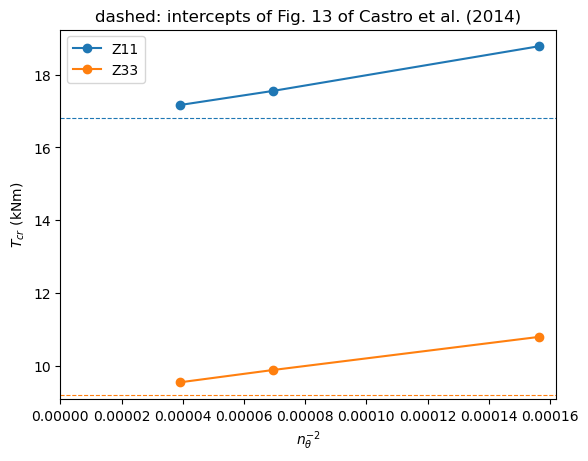

In [6]:
print('%-4s %16s %12s %10s' % ('cyl.', 'T_inf (Nm)', 'Fig. 13', 'rel. diff.'))
for cyl, values in conv_lam.items():
    (n1, T1), (n2, T2) = values[-2:]
    c = (T1 - T2)/(n1**-2. - n2**-2.)
    T_inf = T2 - c*n2**-2.
    print('%-4s %16.1f %12.1f %10.3f' % (cyl, T_inf, T_ref[cyl],
                                         T_inf/T_ref[cyl] - 1))

fig, ax = plt.subplots()
for cyl, values in conv_lam.items():
    ntheta, Tcr = np.array(values).T
    ax.plot(ntheta**-2., Tcr/1e3, 'o-', label=cyl)
    ax.axhline(T_ref[cyl]/1e3, ls='--', color=ax.lines[-1].get_color(), lw=0.8)
ax.set_xlim(left=0)
ax.set_xlabel(r'$n_\theta^{-2}$')
ax.set_ylabel(r'$T_{cr}$ (kNm)')
ax.set_title('dashed: intercepts of Fig. 13 of Castro et al. (2014)')
ax.legend()
plt.show()

The extrapolated torques are within about 1 % of the values read off the
figure, which is the precision with which the figure can be read.

### Buckling mode

The radial displacement of the first mode of Z33, on the finest mesh, on the
unrolled surface: inclined buckles crossing the whole length, the pattern of
torsional buckling:

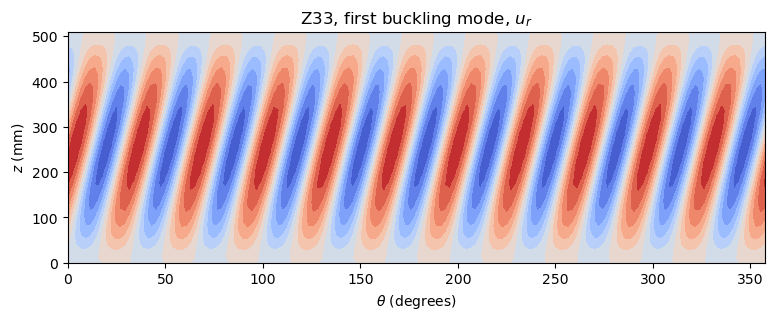

In [7]:
ur = res_lam['eigvecs'][0::DOF, 0].reshape(res_lam['zmesh'].shape)
fig, ax = plt.subplots(figsize=(9, 3))
ax.contourf(np.degrees(res_lam['thetamesh']), res_lam['zmesh']*1e3, ur,
            levels=12, cmap='coolwarm')
ax.set_xlabel(r'$\theta$ (degrees)')
ax.set_ylabel('$z$ (mm)')
ax.set_title('Z33, first buckling mode, $u_r$')
plt.show()

## 2. Isotropic cylinder

An isotropic cylinder with $R = 250$ mm, $L = 4 R$, $t = 4$ mm, $E = 70$ GPa
and $\nu = 0.3$. Its simply supported edges, those of Batdorf et al. (1947,
p. 8), are $w = w_{,xx} = v = 0$ with $u$ unrestrained: only the radial and
circumferential translations are held, dofs 0 and 1 in cylindrical
coordinates. The critical shear stress of Batdorf, Stein and Schildcrout
(1947, p. 3) is

$$
\tau_{cr} = k_s \frac{\pi^2 D}{L^2 t}, \qquad
k_s = 0.85 Z^{3/4}, \qquad
Z = \frac{L^2}{R t} \sqrt{1 - \nu^2}
$$

the straight-line approximation of their Galerkin solution, valid for $100 <
Z < 10 R^2/t^2$ (p. 4); with the correlation factor set to one it is Eq. (25)
of NASA SP-8007 (1968, Sec. 4.2.4, p. 11). The critical shear resultant is
$N_{xy,cr} = \tau_{cr} t$; with the reference $N_{xy} = -1$ N/m the load
multiplier is $N_{xy,cr}$ in N/m:

In [8]:
Ei, nui = 70.e9, 0.3
Ri = 0.250
Li = 4*Ri
ti = 0.004
Di = Ei*ti**3/(12*(1 - nui**2))
Z = Li**2/(Ri*ti)*np.sqrt(1 - nui**2)
k_s = 0.85*Z**0.75
Nxy_ref = k_s*np.pi**2*Di/Li**2
print('Z = %.1f (validity: 100 < Z < %.0f), k_s = %.2f, N_xy,cr = %.1f N/m'
      % (Z, 10*Ri**2/ti**2, k_s, Nxy_ref))

Z = 953.9 (validity: 100 < Z < 39062), k_s = 145.90, N_xy,cr = 590764.7 N/m


In [9]:
prop_iso = isotropic_plate(thickness=ti, E=Ei, nu=nui)
NTHETA_ISOTROPIC = [64, 96, 128]
print('%6s %8s %14s %14s %10s %8s' % ('ntheta', 'elements', 'N_xy,cr (N/m)',
      'Batdorf', 'rel. diff.', 'time'))
for ntheta in NTHETA_ISOTROPIC:
    t0 = time.time()
    res_iso = cylinder_torsion(prop_iso, Ri, Li, ntheta, -1., (0, 1),
                               num_eigvalues=4)
    Ncr = res_iso['eigvals'][0]
    print('%6d %8d %14.1f %14.1f %10.3f %7.0fs'
          % (ntheta, res_iso['num_elements'], Ncr, Nxy_ref, Ncr/Nxy_ref - 1,
             time.time() - t0))

ntheta elements  N_xy,cr (N/m)        Batdorf rel. diff.     time


    64     2560       613634.3       590764.7      0.039      10s


    96     5760       595504.0       590764.7      0.008      34s


   128    10240       589342.8       590764.7     -0.002      73s


Here $Z = 954$, and the element converges to slightly below the formula. The
formula is a straight-line fit of Batdorf's Galerkin solution of a
Donnell-type equation: Table 1, p. 20, of the same report gives $k_s = 153.0$
at $Z = 1000$ in the second approximation, 1.2 % above the 151.2 of the
straight line, so a difference of the order of 1 % is within the accuracy of
the formula itself.

## References

- Batdorf, S. B., Stein, M. and Schildcrout, M., Critical stress of
  thin-walled cylinders in torsion, NACA TN 1344, 1947.
- Castro, S. G. P., Mittelstedt, C., Monteiro, F. A. C., Arbelo, M. A.,
  Ziegmann, G. and Degenhardt, R., Linear buckling predictions of
  unstiffened laminated composite cylinders and cones under various loading
  and boundary conditions using semi-analytical models, Composite
  Structures, 118, 303-315, 2014.
  https://doi.org/10.1016/j.compstruct.2014.07.037
- NASA SP-8007, Buckling of thin-walled circular cylinders, 1965, revised
  1968.